# 02 · Forensic exploration

**Question:** what does the label really measure, how is it produced, and what in the data
could mislead a model?

The dataset's Severity is a 1–4 rating of an accident's **impact on traffic** (delay), not
of injury or death. Notebook 01 built the population; this notebook shows the evidence
behind it and maps missingness, outliers, space, time, weather and road context.

In [1]:
import json

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.metrics import mutual_info_score

from accidents import clean, config, evaluate, export, features, ingest, plots

plots.use_style()
pd.set_option("display.width", 140)

# Only the columns and rows each section needs: the full table is several GB in memory.
raw = ingest.read_parquet(["Source", "Severity", "Start_Time"])
population = clean.mask_impossible_readings(
    clean.target_window(ingest.read_parquet(ingest.POPULATION_COLUMNS, ingest.POPULATION_ROWS))
)
print(f"raw {len(raw):,} rows; population {len(population):,} rows")

raw 7,728,394 rows; population 3,242,942 rows


## 1 · Each source uses its own severity scale

The data comes from several traffic feeds ("Source1–3"). If they shared one scale, the
severity mix would look alike across sources and stay steady over time.

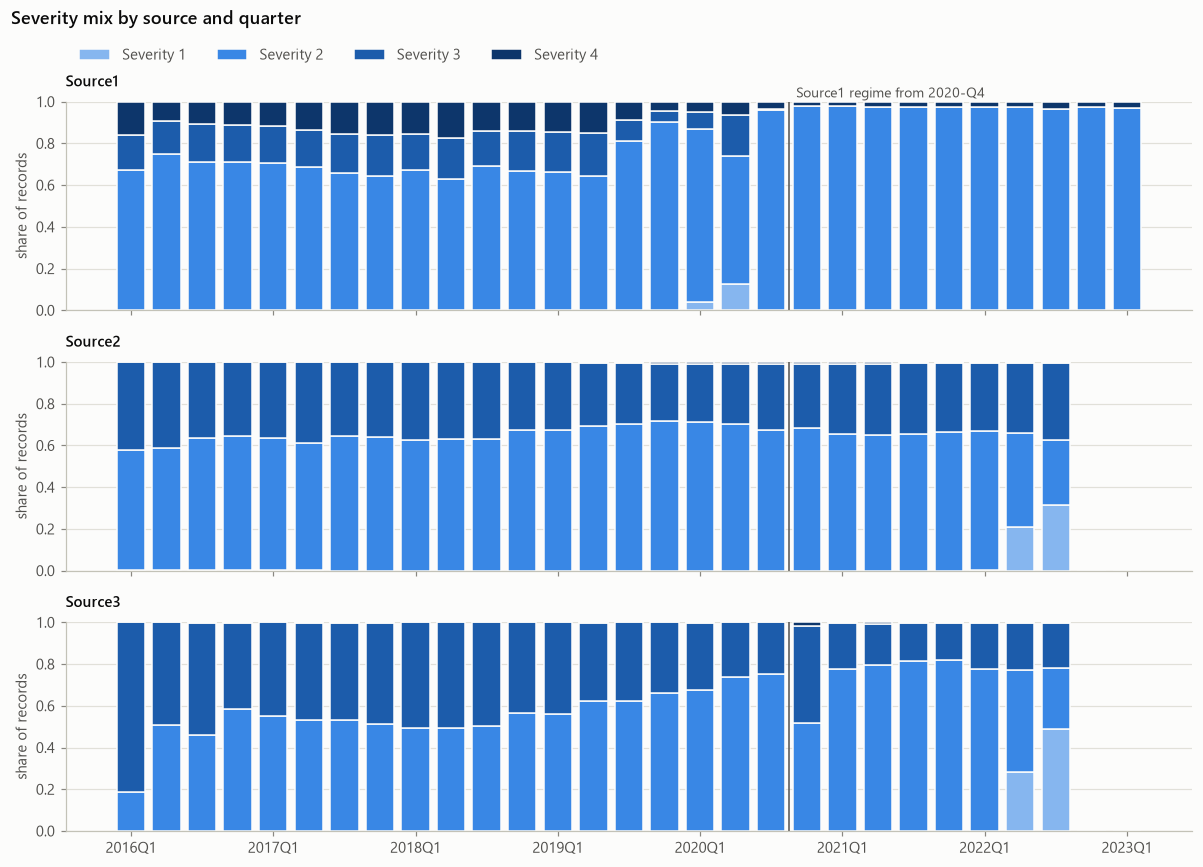

In [2]:
raw["quarter"] = raw["Start_Time"].dt.to_period("Q")
share = (
    raw.groupby(["Source", "quarter"])["Severity"]
    .value_counts(normalize=True)
    .unstack(fill_value=0)
)
levels = [1, 2, 3, 4]
level_colors = [plots.BLUE_RAMP[i] for i in (3, 6, 9, 12)]  # ordinal: light → dark
quarters = sorted(raw["quarter"].unique())
fig, axes = plt.subplots(3, 1, figsize=(11, 8), sharex=True)
for ax, source in zip(axes, ["Source1", "Source2", "Source3"], strict=True):
    table = share.loc[source].reindex(quarters, fill_value=np.nan)
    x = np.arange(len(quarters))
    bottom = np.zeros(len(quarters))
    for level, color in zip(levels, level_colors, strict=True):
        values = table[level].fillna(0).to_numpy()
        ax.bar(
            x,
            values,
            bottom=bottom,
            width=0.8,
            color=color,
            edgecolor=plots.SURFACE,
            linewidth=1,
            label=f"Severity {level}",
        )
        bottom += values
    ax.set_ylim(0, 1)
    ax.set_ylabel("share of records")
    ax.set_title(source, fontsize=10)
    ax.grid(axis="x", visible=False)
axes[0].legend(ncol=4, loc="lower left", bbox_to_anchor=(0, 1.12))
axes[-1].set_xticks(np.arange(0, len(quarters), 4))
axes[-1].set_xticklabels([str(quarters[i]) for i in range(0, len(quarters), 4)])
regime = quarters.index(pd.Period(config.REGIME_START, "Q"))
for ax in axes:
    ax.axvline(regime - 0.5, color=plots.INK_SECONDARY, linewidth=1)
axes[0].text(
    regime - 0.3,
    1.02,
    "Source1 regime from 2020-Q4",
    color=plots.INK_SECONDARY,
    fontsize=9,
    transform=axes[0].get_xaxis_transform(),
)
fig.suptitle("Severity mix by source and quarter", x=0.01, ha="left", fontweight="semibold")
plt.tight_layout()
plt.show()

In [3]:
regime_share = share.loc["Source1"].loc[pd.Period(config.REGIME_START, "Q") :]
print("Source1 severity share since 2020-Q4 (min / max across quarters):")
display(regime_share.agg(["min", "max"]).round(4))

Source1 severity share since 2020-Q4 (min / max across quarters):


Severity,1,2,3,4
min,0.0,0.9661,0.0,0.0194
max,0.0,0.9806,0.0,0.0339


## 2 · The old binary target followed the source mix

The original project labelled Severity 3–4 as "severe" across all sources. When Source2
stopped reporting, that label's rate collapsed even though roads did not change.

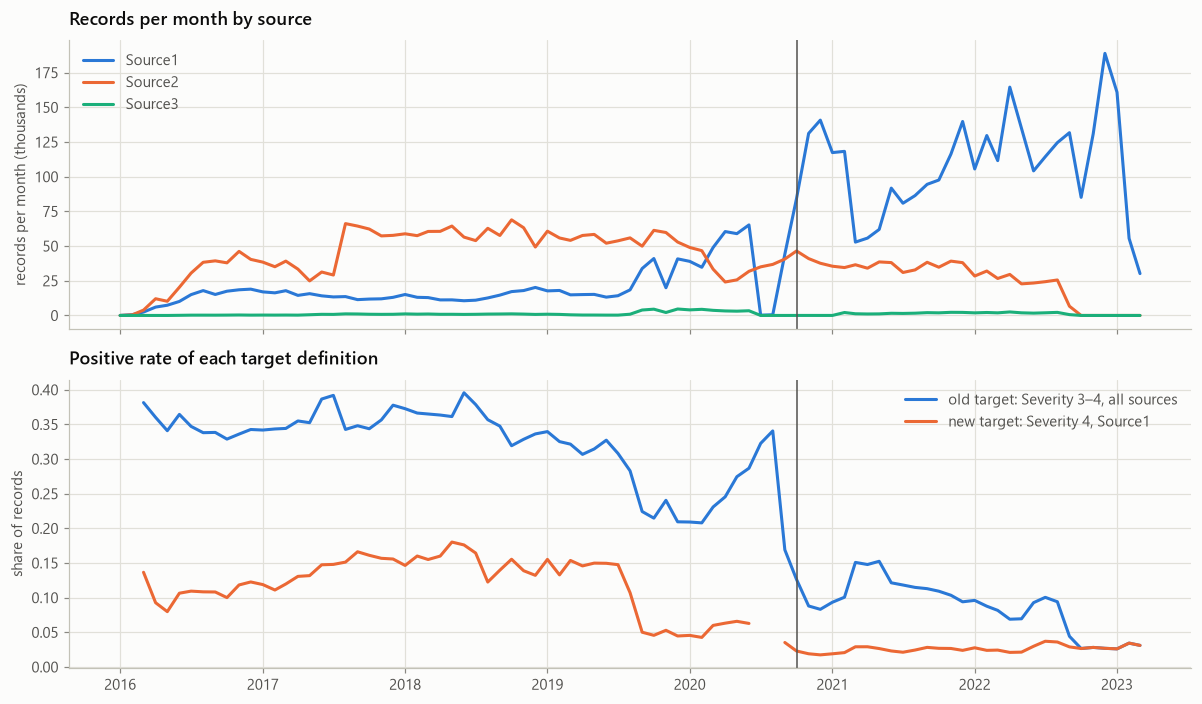

Old target rate by source, Mar 2022 – Mar 2023 (the old project's window):


,n,positives,rate,low,high
Source,,,,,
Source1,1537626,42869,0.0279,0.0276,0.0281
Source2,158968,55144,0.3469,0.3446,0.3492
Source3,12752,2849,0.2234,0.2163,0.2307


In [4]:
raw["month"] = raw["Start_Time"].dt.to_period("M")
volume = raw.groupby(["month", "Source"]).size().unstack(fill_value=0)
# Rates from months with under 1,000 records are noise (early 2016, a mid-2020 gap).
old_rate = raw.groupby("month")["Severity"].apply(
    lambda s: (s >= 3).mean() if len(s) >= 1000 else np.nan
)
s1 = raw[raw["Source"] == "Source1"]
new_rate = s1.groupby("month")["Severity"].apply(
    lambda s: (s == 4).mean() if len(s) >= 1000 else np.nan
)
x = volume.index.to_timestamp()

fig, (top, bottom) = plt.subplots(2, 1, figsize=(11, 6.5), sharex=True)
for i, source in enumerate(["Source1", "Source2", "Source3"]):
    top.plot(x, volume[source] / 1000, color=plots.SERIES[i], label=source)
top.set_ylabel("records per month (thousands)")
top.set_title("Records per month by source")
top.legend(loc="upper left")
bottom.plot(
    x,
    old_rate.reindex(volume.index),
    color=plots.SERIES[0],
    label="old target: Severity 3–4, all sources",
)
bottom.plot(
    x,
    new_rate.reindex(volume.index),
    color=plots.SERIES[1],
    label="new target: Severity 4, Source1",
)
bottom.set_ylabel("share of records")
bottom.set_title("Positive rate of each target definition")
bottom.legend(loc="upper right")
for ax in (top, bottom):
    ax.axvline(pd.Timestamp(config.REGIME_START), color=plots.INK_SECONDARY, linewidth=1)
plt.tight_layout()
plt.show()

rolling = raw[(raw["Start_Time"] >= "2022-03-01") & (raw["Start_Time"] < "2023-04-01")]
by_source = evaluate.rate_table((rolling["Severity"] >= 3).astype(int), rolling["Source"])
print("Old target rate by source, Mar 2022 – Mar 2023 (the old project's window):")
display(by_source.round(4))
del raw, rolling, s1  # the remaining sections use the population only

## 3 · The target inside the stable regime

Monthly Severity-4 rate with its 95% interval, and the volume it rests on.

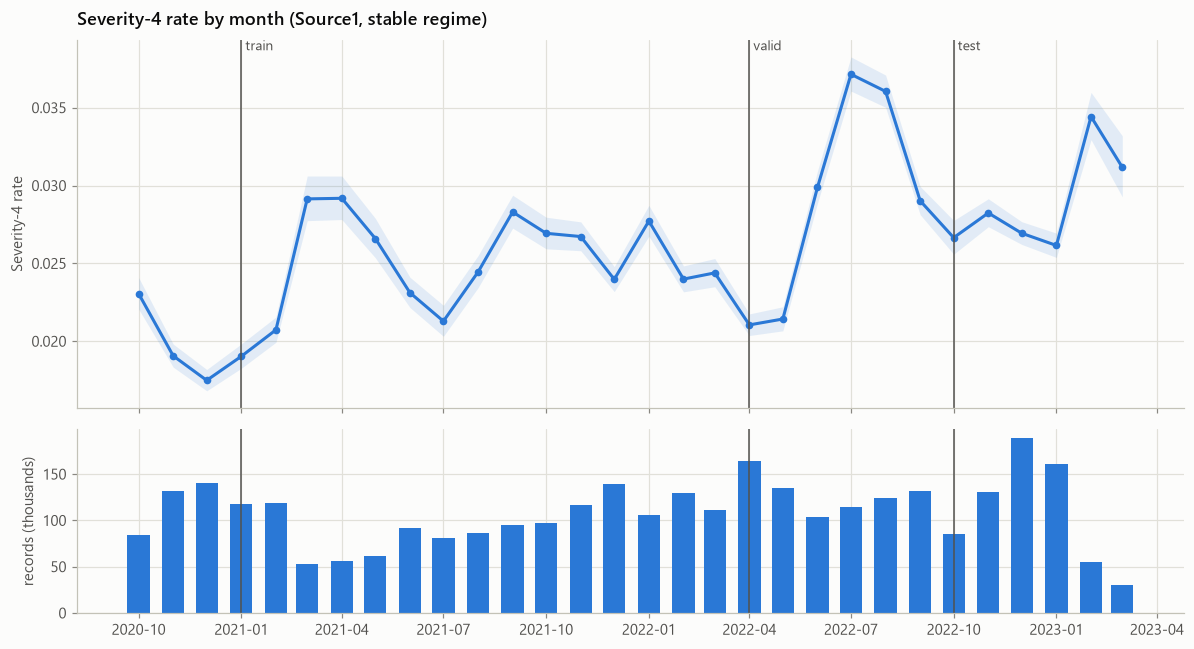

month,2020-10,2020-11,2020-12,2021-01,2021-02,2021-03,2021-04,2021-05,2021-06,2021-07,...,2022-06,2022-07,2022-08,2022-09,2022-10,2022-11,2022-12,2023-01,2023-02,2023-03
n,84352.0000,131220.0000,140799.0000,117396.0000,118289.0000,52878.0000,55758.0000,61998.0000,91794.0000,80893.0000,...,104207.0000,114413.0000,124562.0000,131744.0000,85135.0000,130959.0000,188908.0000,160914.0000,55532.0000,30187.0000
rate,0.0231,0.0191,0.0175,0.0190,0.0207,0.0291,0.0292,0.0266,0.0231,0.0213,...,0.0299,0.0371,0.0360,0.0290,0.0267,0.0282,0.0269,0.0262,0.0344,0.0312
low,0.0221,0.0183,0.0168,0.0183,0.0199,0.0277,0.0278,0.0254,0.0222,0.0203,...,0.0289,0.0361,0.0350,0.0281,0.0256,0.0274,0.0262,0.0254,0.0329,0.0293
high,0.0241,0.0198,0.0182,0.0198,0.0216,0.0306,0.0306,0.0279,0.0241,0.0223,...,0.0309,0.0383,0.0371,0.0299,0.0278,0.0291,0.0277,0.0269,0.0360,0.0332


In [5]:
population["month"] = population["Start_Time"].dt.to_period("M")
monthly = evaluate.rate_table(population["y"], population["month"])
x = monthly.index.to_timestamp()
fig, (top, bottom) = plt.subplots(
    2, 1, figsize=(11, 6), sharex=True, gridspec_kw={"height_ratios": [2, 1]}
)
top.fill_between(x, monthly["low"], monthly["high"], color=plots.SERIES[0], alpha=0.12, linewidth=0)
top.plot(x, monthly["rate"], color=plots.SERIES[0], marker="o", markersize=4)
top.set_ylabel("Severity-4 rate")
top.set_title("Severity-4 rate by month (Source1, stable regime)")
for start, label in [
    (config.TRAIN_START, "train"),
    (config.VALID_START, "valid"),
    (config.TEST_START, "test"),
]:
    for ax in (top, bottom):
        ax.axvline(pd.Timestamp(start), color=plots.INK_SECONDARY, linewidth=1)
    top.text(
        pd.Timestamp(start),
        1.0,
        f" {label}",
        transform=top.get_xaxis_transform(),
        va="top",
        color=plots.INK_SECONDARY,
        fontsize=9,
    )
bottom.bar(x, monthly["n"] / 1000, width=20, color=plots.SERIES[0])
bottom.set_ylabel("records (thousands)")
plt.tight_layout()
plt.show()
display(monthly[["n", "rate", "low", "high"]].T.round(4))

## 4 · Missing weather readings

Weather comes from the nearest airport station. If readings went missing at random,
columns would be missing independently and missingness would not relate to the label.

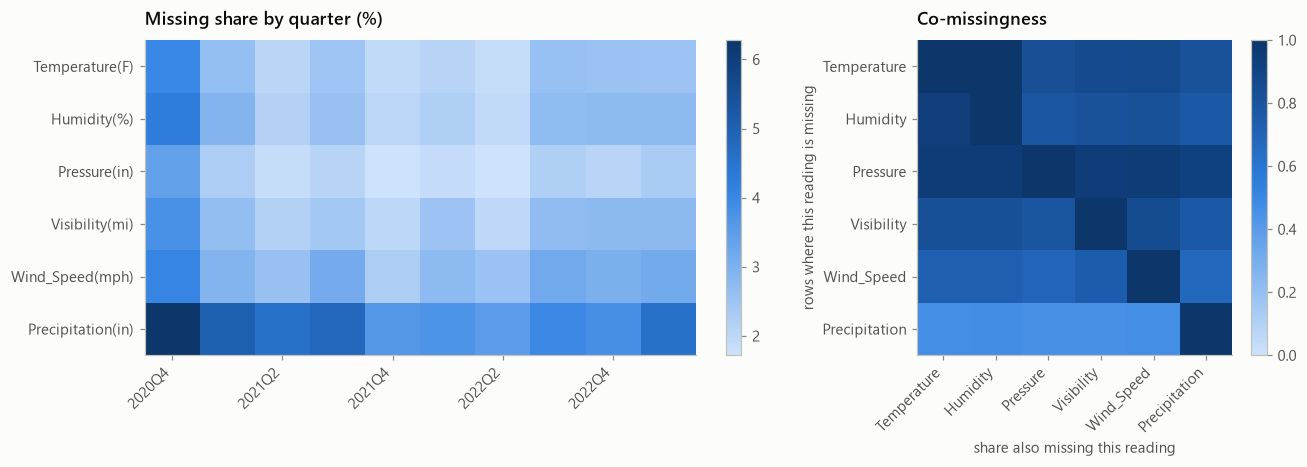

n    rate     low    high
column            reading                                   
Temperature(F)    missing    80199.0  0.0446  0.0432  0.0461
                  present  3162743.0  0.0251  0.0250  0.0253
Humidity(%)       missing    85218.0  0.0437  0.0423  0.0451
                  present  3157724.0  0.0251  0.0249  0.0253
Pressure(in)      missing    69688.0  0.0462  0.0446  0.0478
                  present  3173254.0  0.0252  0.0250  0.0253
Visibility(mi)    missing    83594.0  0.0454  0.0441  0.0469
                  present  3159348.0  0.0251  0.0249  0.0253
Wind_Speed(mph)   missing    95795.0  0.0410  0.0398  0.0423
                  present  3147147.0  0.0251  0.0250  0.0253
Precipitation(in) missing   140183.0  0.0348  0.0339  0.0358
                  present  3102759.0  0.0252  0.0250  0.0254

In [6]:
weather = list(features.WEATHER_COLUMNS)
population["quarter"] = population["Start_Time"].dt.to_period("Q")
missing_by_quarter = population.groupby("quarter")[weather].apply(lambda d: d.isna().mean() * 100)
missing = population[weather].isna()
co_missing = pd.DataFrame(
    {b: [missing.loc[missing[a], b].mean() for a in weather] for b in weather}, index=weather
)

fig, (left, right) = plt.subplots(1, 2, figsize=(12, 4.2), gridspec_kw={"width_ratios": [1.6, 1]})
image = left.imshow(missing_by_quarter.T, aspect="auto", cmap=plots.SEQUENTIAL)
left.set_yticks(range(len(weather)), weather)
left.set_xticks(
    range(0, len(missing_by_quarter), 2),
    [str(q) for q in missing_by_quarter.index[::2]],
    rotation=45,
    ha="right",
)
left.set_title("Missing share by quarter (%)")
left.grid(False)
fig.colorbar(image, ax=left, fraction=0.03)
image = right.imshow(co_missing, vmin=0, vmax=1, cmap=plots.SEQUENTIAL)
right.set_xticks(range(len(weather)), [w.split("(")[0] for w in weather], rotation=45, ha="right")
right.set_yticks(range(len(weather)), [w.split("(")[0] for w in weather])
right.set_title("Co-missingness")
right.set_ylabel("rows where this reading is missing")
right.set_xlabel("share also missing this reading")
right.grid(False)
fig.colorbar(image, ax=right, fraction=0.046)
plt.tight_layout()
plt.show()

rows = []
for column in weather:
    for state, mask in (("missing", missing[column]), ("present", ~missing[column])):
        table = evaluate.rate_table(
            population.loc[mask, "y"], pd.Series("all", index=mask[mask].index)
        )
        rows.append({"column": column, "reading": state, **table.iloc[0].to_dict()})
missing_vs_label = pd.DataFrame(rows).set_index(["column", "reading"])
display(missing_vs_label[["n", "rate", "low", "high"]].round(4))

## 5 · Weather readings after masking impossible values

Distributions inside the physical bounds (notebook 01, section 4), log-scaled counts so
the tails stay visible.

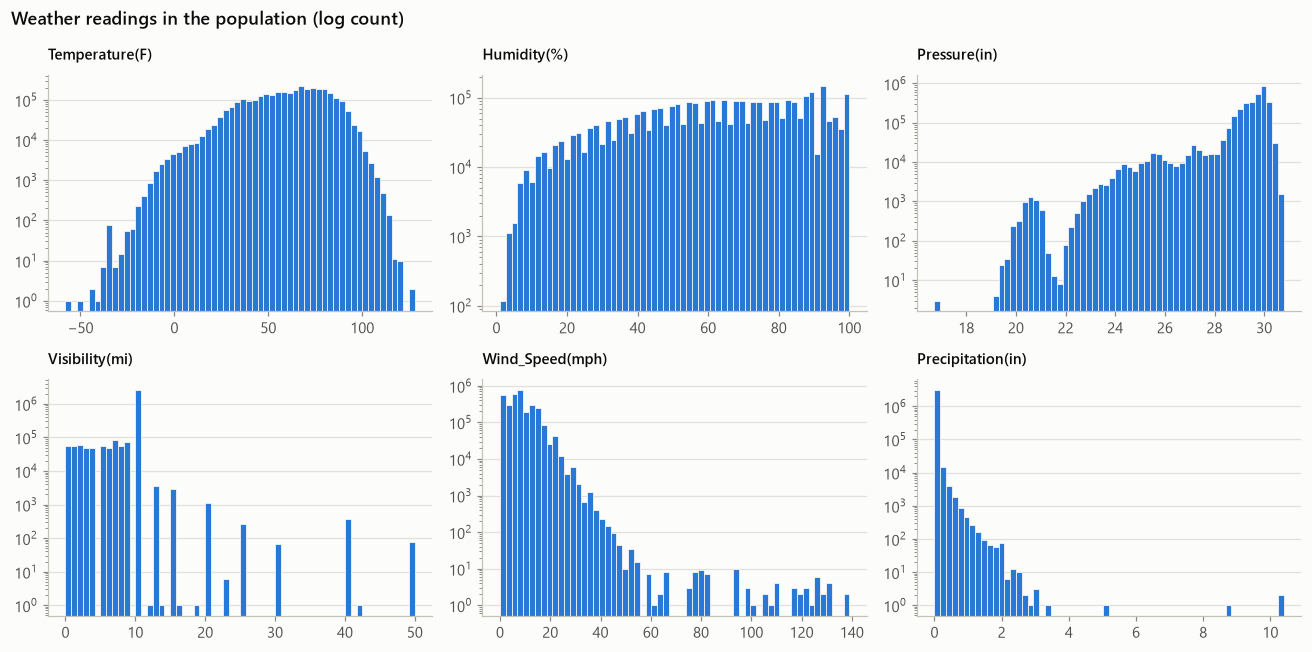

In [7]:
fig, axes = plt.subplots(2, 3, figsize=(12, 6))
for ax, column in zip(axes.flat, weather, strict=True):
    values = population[column].dropna()
    ax.hist(values, bins=60, color=plots.SERIES[0], edgecolor=plots.SURFACE, linewidth=0.5)
    ax.set_yscale("log")
    ax.set_title(column, fontsize=10)
    ax.grid(axis="x", visible=False)
fig.suptitle(
    "Weather readings in the population (log count)", x=0.01, ha="left", fontweight="semibold"
)
plt.tight_layout()
plt.show()

## 6 · Where accidents and Severity-4 accidents happen

Hexagon bins over longitude and latitude. The right map shows the Severity-4 rate in bins
with at least 200 records.

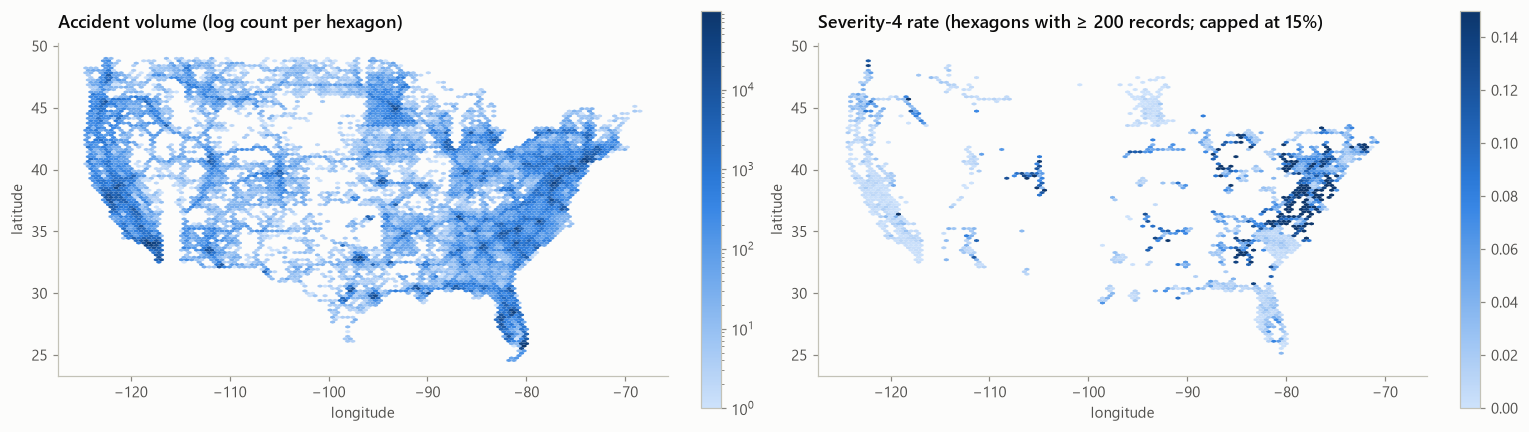

In [8]:
fig, (left, right) = plt.subplots(1, 2, figsize=(14, 4.8))
hb = left.hexbin(
    population["Start_Lng"],
    population["Start_Lat"],
    gridsize=110,
    bins="log",
    cmap=plots.SEQUENTIAL,
    mincnt=1,
    linewidths=0,
)
left.set_title("Accident volume (log count per hexagon)")
fig.colorbar(hb, ax=left, fraction=0.03)
hb = right.hexbin(
    population["Start_Lng"],
    population["Start_Lat"],
    C=population["y"],
    reduce_C_function=np.mean,
    gridsize=110,
    mincnt=200,
    cmap=plots.SEQUENTIAL,
    vmax=0.15,
    linewidths=0,
)
right.set_title("Severity-4 rate (hexagons with ≥ 200 records; capped at 15%)")
fig.colorbar(hb, ax=right, fraction=0.03)
for ax in (left, right):
    ax.set_aspect(1.25)
    ax.grid(False)
    ax.set_xlabel("longitude")
    ax.set_ylabel("latitude")
plt.tight_layout()
plt.show()

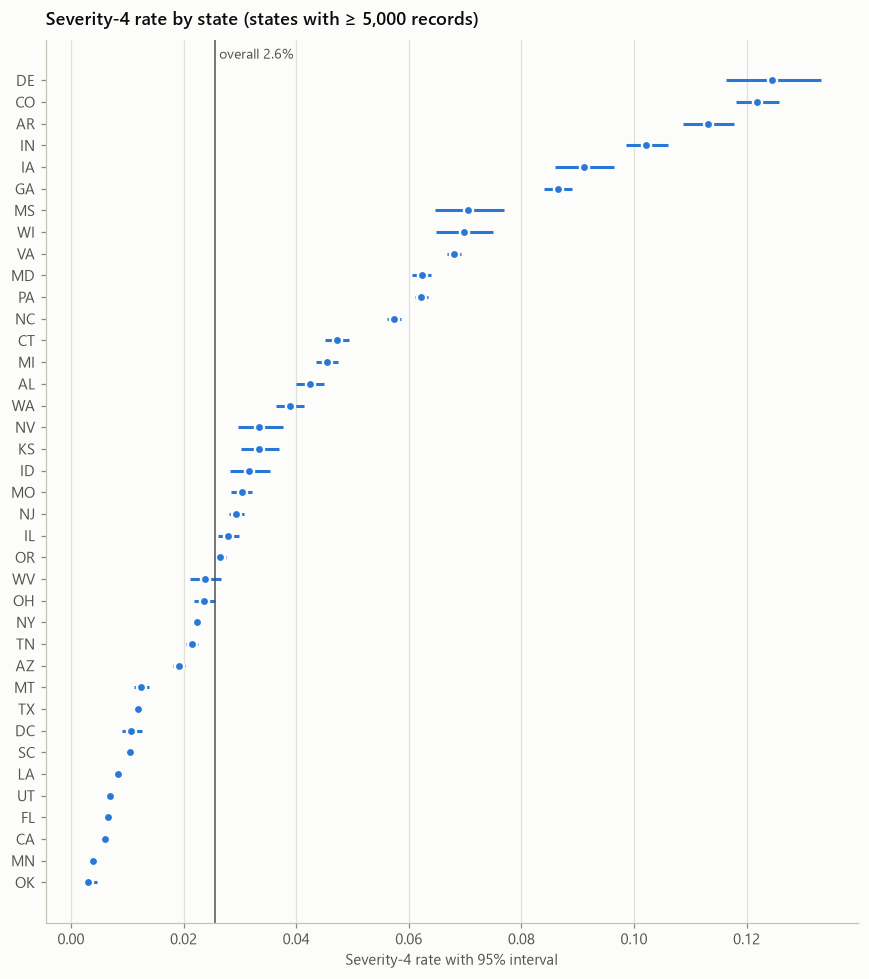

highest/lowest state rate ratio: 40×


In [9]:
by_state = evaluate.rate_table(population["y"], population["State"], min_count=5000)
by_state = by_state.sort_values("rate")
overall = population["y"].mean()
fig, ax = plt.subplots(figsize=(8, 9))
yy = np.arange(len(by_state))
ax.hlines(yy, by_state["low"], by_state["high"], color=plots.SERIES[0], linewidth=2)
ax.plot(
    by_state["rate"],
    yy,
    "o",
    color=plots.SERIES[0],
    markeredgecolor=plots.SURFACE,
    markeredgewidth=1.5,
    markersize=6,
)
ax.axvline(overall, color=plots.INK_SECONDARY, linewidth=1)
ax.text(overall, len(by_state), f" overall {overall:.1%}", color=plots.INK_SECONDARY, fontsize=9)
ax.set_yticks(yy, by_state.index)
ax.set_xlabel("Severity-4 rate with 95% interval")
ax.set_title("Severity-4 rate by state (states with ≥ 5,000 records)")
ax.grid(axis="y", visible=False)
plt.tight_layout()
plt.show()
print(f"highest/lowest state rate ratio: {by_state['rate'].max() / by_state['rate'].min():.0f}×")

## 7 · When: hour of day × day of week

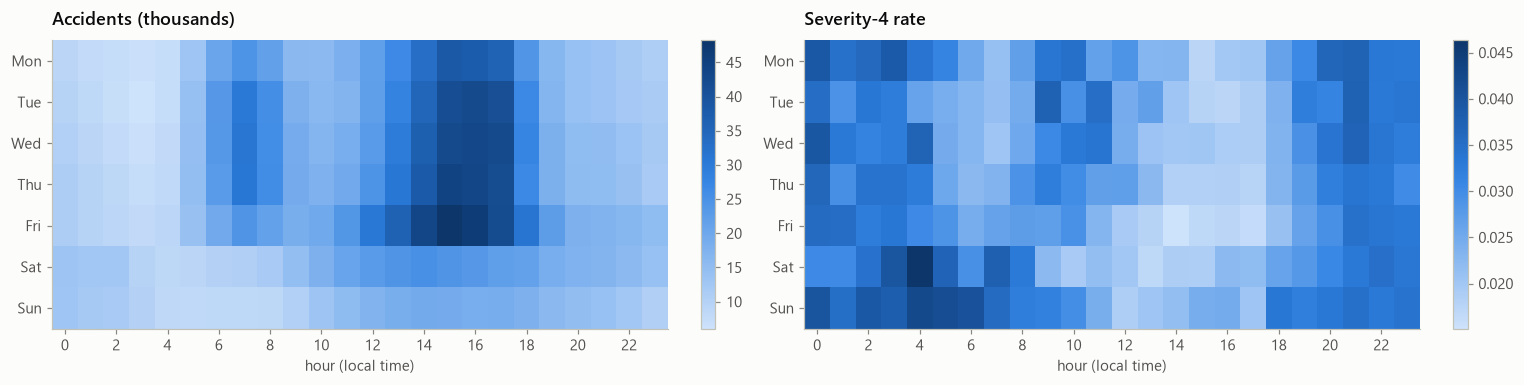

In [10]:
times = features.time_features(population["Start_Time"])
days = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]
volume_grid = population.groupby([times["weekday"], times["hour"]]).size().unstack()
rate_grid = population["y"].groupby([times["weekday"], times["hour"]]).mean().unstack()
fig, axes = plt.subplots(1, 2, figsize=(14, 3.6))
for ax, grid, title in [
    (axes[0], volume_grid / 1000, "Accidents (thousands)"),
    (axes[1], rate_grid, "Severity-4 rate"),
]:
    image = ax.imshow(grid, aspect="auto", cmap=plots.SEQUENTIAL)
    ax.set_yticks(range(7), days)
    ax.set_xticks(range(0, 24, 2))
    ax.set_xlabel("hour (local time)")
    ax.set_title(title)
    ax.grid(False)
    fig.colorbar(image, ax=ax, fraction=0.03)
plt.tight_layout()
plt.show()

## 8 · Weather, road and roadside context

Severity-4 rate with 95% intervals for each category; the vertical line is the overall rate.

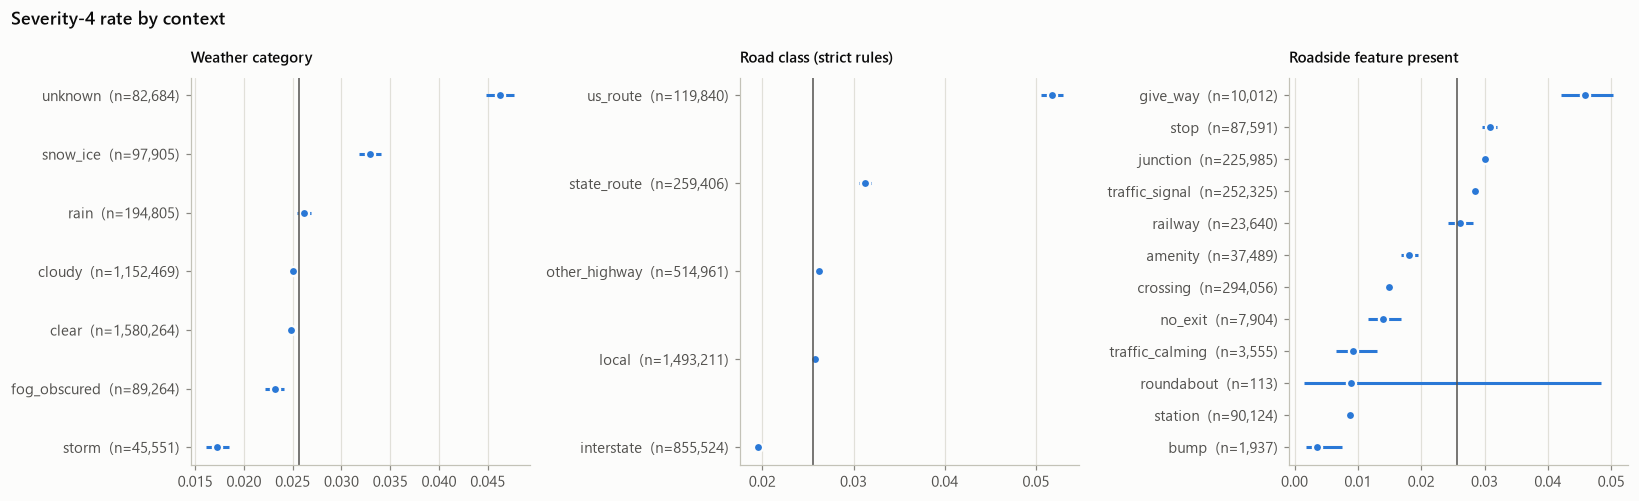

,n,positives,rate,low,high
road class,,,,,
interstate,855524,16699,0.0195,0.0192,0.0198
local,1493211,38509,0.0258,0.0255,0.0260
other_highway,514961,13528,0.0263,0.0258,0.0267
state_route,259406,8101,0.0312,0.0306,0.0319
us_route,119840,6201,0.0517,0.0505,0.0530


In [11]:
context = pd.DataFrame(
    {
        "weather": features.map_unique(population["Weather_Condition"], features.weather_category),
        "road class": features.map_unique(population["Street"], features.road_class),
    }
)
poi_rows = []
for raw_name, name in features.POI_COLUMNS.items():
    flagged = population[raw_name]
    table = evaluate.rate_table(
        population.loc[flagged, "y"], pd.Series(name, index=flagged[flagged].index)
    )
    poi_rows.append(table)
poi = pd.concat(poi_rows)

panels = [
    ("Weather category", evaluate.rate_table(population["y"], context["weather"])),
    ("Road class (strict rules)", evaluate.rate_table(population["y"], context["road class"])),
    ("Roadside feature present", poi),
]
fig, axes = plt.subplots(1, 3, figsize=(15, 4.6))
for ax, (title, table) in zip(axes, panels, strict=True):
    table = table.sort_values("rate")
    yy = np.arange(len(table))
    ax.hlines(yy, table["low"], table["high"], color=plots.SERIES[0], linewidth=2)
    ax.plot(
        table["rate"],
        yy,
        "o",
        color=plots.SERIES[0],
        markeredgecolor=plots.SURFACE,
        markeredgewidth=1.5,
    )
    ax.axvline(overall, color=plots.INK_SECONDARY, linewidth=1)
    ax.set_yticks(yy, [f"{i}  (n={n:,})" for i, n in zip(table.index, table["n"], strict=True)])
    ax.set_title(title, fontsize=10)
    ax.grid(axis="y", visible=False)
fig.suptitle("Severity-4 rate by context", x=0.01, ha="left", fontweight="semibold")
plt.tight_layout()
plt.show()
display(panels[1][1].round(4))

### The original `Is_Highway` rule

The original notebooks flagged a highway if the street contained any of a keyword list
that included "St" and "State", matched as lower-case substrings.

In [12]:
old_keywords = [
    "I-",
    "Interstate",
    "Hwy",
    "Highway",
    "Route",
    "St",
    "State",
    "Turnpike",
    "Fwy",
    "Freeway",
    "Expy",
    "Expressway",
    "Pkwy",
    "Parkway",
    "US-",
    "U.S.",
    "Loop",
    "Bypass",
]
street = population["Street"].fillna("").str.lower()
old_flag = street.apply(lambda s: any(k.lower() in s for k in old_keywords))
print(f"old rule flags {old_flag.mean():.1%} of records as highway")
print(
    "examples it calls highway:",
    population.loc[old_flag & (context["road class"] == "local"), "Street"]
    .value_counts()
    .head(8)
    .index.tolist(),
)

old rule flags 57.1% of records as highway


examples it calls highway: [' SW 8th St', ' Main St', ' SW 88th St', ' W Flagler St', ' N Main St', ' NW 36th St', ' S Main St', ' NE 125th St']


## 9 · Rate against each weather reading

Records split into 20 equal-count bins per reading; Severity-4 rate with its interval in
each bin. Visibility and precipitation are mostly one value (10 mi, 0 in), so they get
fixed edges instead. A flat line means the reading carries little signal on its own.

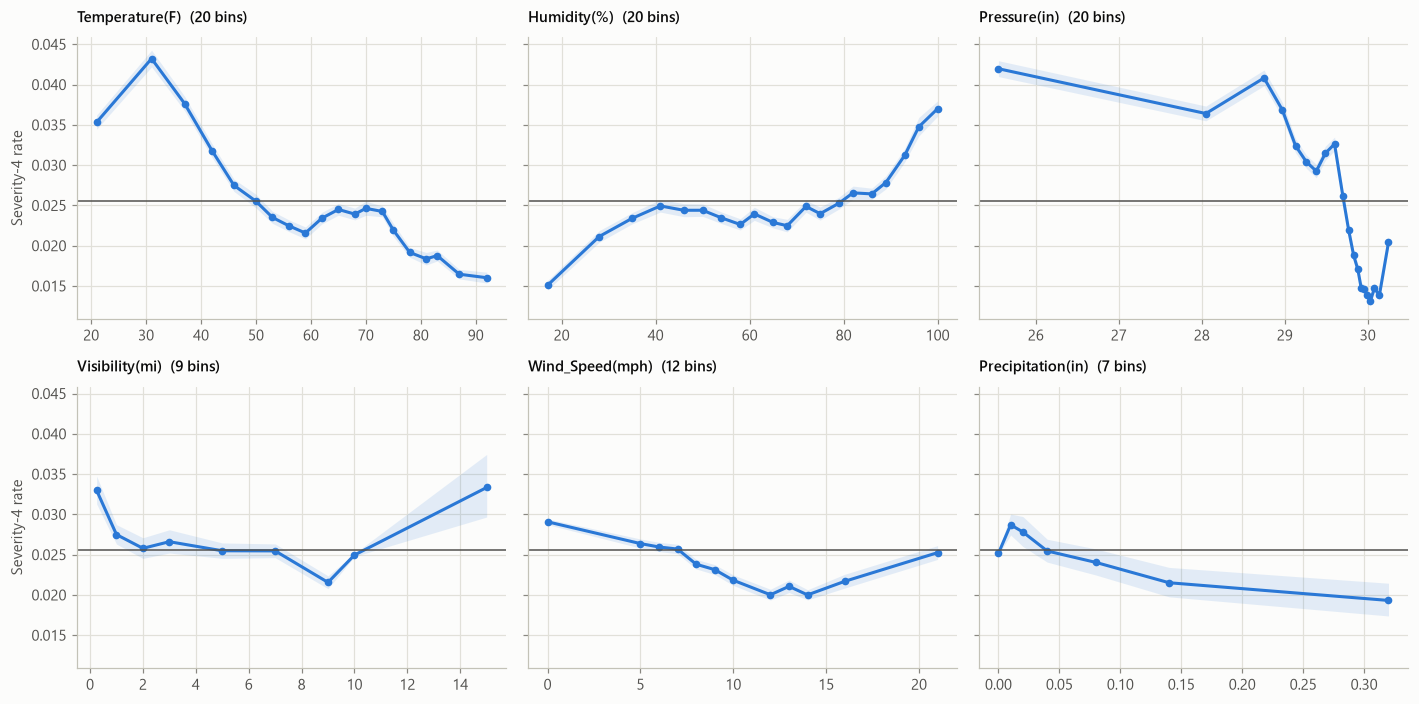

In [13]:
fixed_edges = {
    "Visibility(mi)": [0, 0.5, 1, 2, 3, 5, 7, 9.99, 10, 50],
    "Precipitation(in)": [0, 1e-9, 0.01, 0.02, 0.05, 0.1, 0.2, 12],
}
fig, axes = plt.subplots(2, 3, figsize=(13, 6.5), sharey=True)
for ax, column in zip(axes.flat, weather, strict=True):
    values = population[column]
    if column in fixed_edges:
        bins = pd.cut(values, fixed_edges[column], include_lowest=True)
    else:
        bins = pd.qcut(values, 20, duplicates="drop")
    table = evaluate.rate_table(population["y"], bins)
    centres = population.groupby(bins, observed=True)[column].median()
    ax.fill_between(
        centres, table["low"], table["high"], color=plots.SERIES[0], alpha=0.12, linewidth=0
    )
    ax.plot(centres, table["rate"], color=plots.SERIES[0], marker="o", markersize=4)
    ax.axhline(overall, color=plots.INK_SECONDARY, linewidth=1)
    ax.set_title(f"{column}  ({len(table)} bins)", fontsize=10)
axes[0, 0].set_ylabel("Severity-4 rate")
axes[1, 0].set_ylabel("Severity-4 rate")
plt.tight_layout()
plt.show()

## 10 · How much each candidate feature says about the label

Mutual information with the label on a stratified 400k sample (in nats; 0 = independent).
It captures non-linear and categorical association, unlike a correlation coefficient.

Every numeric feature is cut into the same 20 equal-count bins, with missing values as
their own bin, and scored with the plain discrete estimator. A first run used
scikit-learn's nearest-neighbour estimator for continuous features; it scored visibility
six times higher than anything else, which contradicts visibility's nearly flat rate curve
in section 9. That estimator is known to inflate on heavily tied values (most visibility
readings are exactly 10 mi), so one estimator for every feature is the fairer comparison.

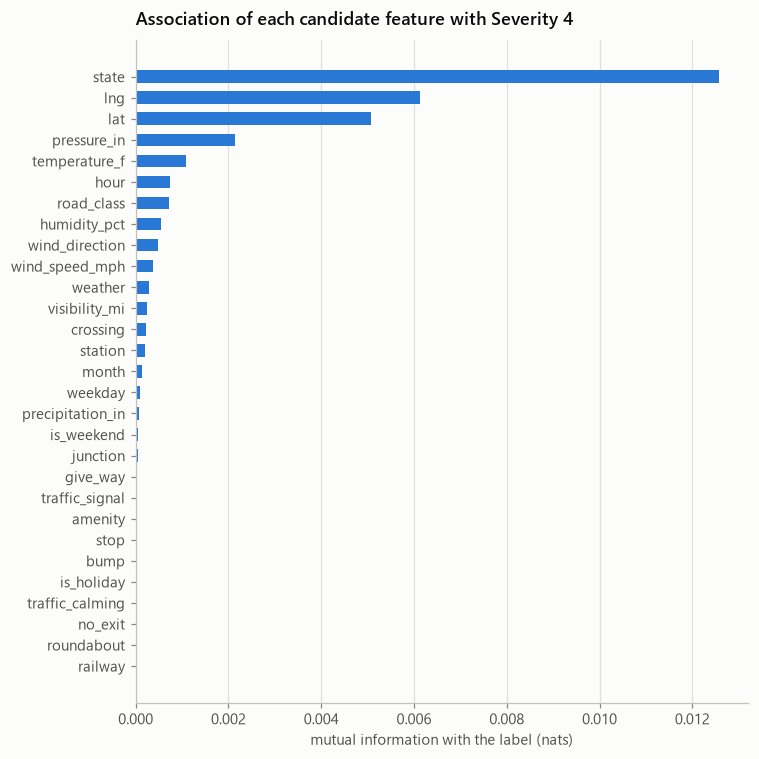

In [14]:
sample = population.groupby("y", group_keys=False).sample(
    frac=400_000 / len(population), random_state=config.SEED
)
candidates = pd.DataFrame(
    {
        "lat": sample["Start_Lat"], "lng": sample["Start_Lng"],
        **{name: sample[raw_name] for raw_name, name in features.WEATHER_COLUMNS.items()},
        **features.time_features(sample["Start_Time"]).to_dict("series"),
        **{name: sample[raw_name].astype(int) for raw_name, name in features.POI_COLUMNS.items()},
        "state": sample["State"].astype("category").cat.codes,
        "road_class": context.loc[sample.index, "road class"].astype("category").cat.codes,
        "weather": context.loc[sample.index, "weather"].astype("category").cat.codes,
        "wind_direction": sample["Wind_Direction"].astype("category").cat.codes,
    }
)  # fmt: skip
continuous = ["lat", "lng", *features.WEATHER_COLUMNS.values()]
mi = {}
for column in candidates:
    values = candidates[column]
    if column in continuous:
        values = pd.qcut(values, 20, duplicates="drop").cat.codes  # NaN becomes code -1
    mi[column] = mutual_info_score(sample["y"], values)
mi = pd.Series(mi).sort_values()
fig, ax = plt.subplots(figsize=(7, 7))
ax.barh(mi.index, mi.values, height=0.6, color=plots.SERIES[0])
ax.set_xlabel("mutual information with the label (nats)")
ax.set_title("Association of each candidate feature with Severity 4")
ax.grid(axis="y", visible=False)
plt.tight_layout()
plt.show()

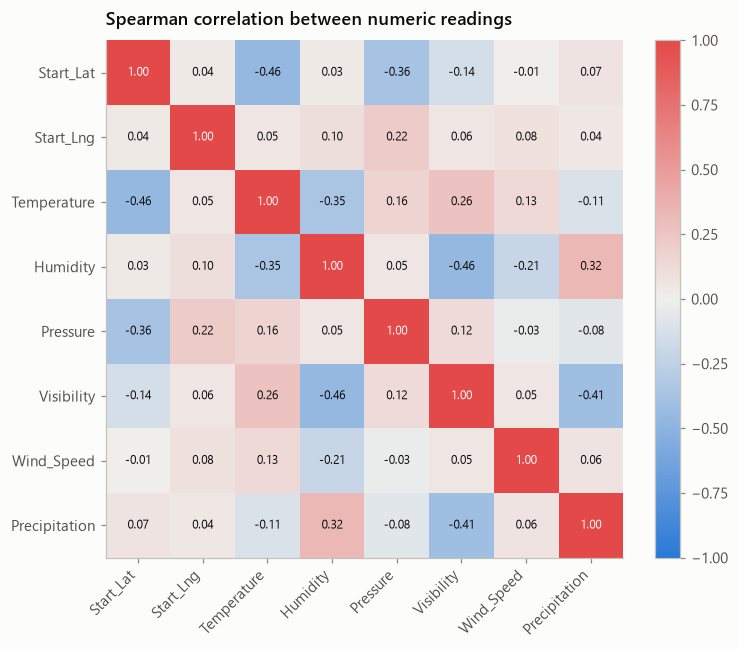

In [15]:
numeric = population[["Start_Lat", "Start_Lng", *weather]].sample(300_000, random_state=config.SEED)
corr = numeric.corr(method="spearman")
fig, ax = plt.subplots(figsize=(7, 6))
image = ax.imshow(corr, vmin=-1, vmax=1, cmap=plots.DIVERGING)
labels = [c.split("(")[0] for c in corr.columns]
ax.set_xticks(range(len(labels)), labels, rotation=45, ha="right")
ax.set_yticks(range(len(labels)), labels)
for i in range(len(labels)):
    for j in range(len(labels)):
        value = corr.iloc[i, j]
        ax.text(
            j,
            i,
            f"{value:.2f}",
            ha="center",
            va="center",
            fontsize=8,
            color=plots.SURFACE if abs(value) > 0.6 else plots.INK,
        )
ax.set_title("Spearman correlation between numeric readings")
ax.grid(False)
fig.colorbar(image, ax=ax, fraction=0.046)
plt.tight_layout()
plt.show()

## Saved for the dashboard

The dashboard's story numbers come from this file, never typed by hand.

In [16]:
STORY = config.ROOT / "data" / "processed" / "story"
STORY.mkdir(parents=True, exist_ok=True)
eda = {
    "severity_mix": export.records(share.rename(columns=str)),
    "old_target_rate_by_source": export.records(by_source),
    "monthly_rate": export.records(monthly),
    "state_rates": export.records(by_state),
    "missing_vs_label": export.records(missing_vs_label),
    "weather_rates": export.records(panels[0][1]),
    "road_class_rates": export.records(panels[1][1]),
    "old_highway_share": float(old_flag.mean()),
    "mutual_information": mi.round(6).to_dict(),
}
(STORY / "eda.json").write_text(json.dumps(eda, indent=2))
print("saved", STORY / "eda.json")

saved data\processed\story\eda.json


## Decisions and evidence

**What the label is.** Each source rates severity on its own scale. Since 2020-Q4, Source1
uses only Severity 2 (96.6–98.1% per quarter) and 4 (1.9–3.4%); Source2 and Source3 use all
four levels with about a third at Severity 3. Before 2020-Q4, Source1 itself used all four.
→ **D4:** model Source1's stable regime only, with Severity 4 vs 2.

**Why the old target failed.** In the old project's window, "Severity 3–4" was 2.8% of
Source1 records, 34.7% of Source2 and 22.3% of Source3. That rate collapsed when Source2
stopped reporting in late 2022, with no change in the roads. A model of that target mostly
learns which feed a record came from.

**Drift inside the regime.** The monthly Severity-4 rate moves between 1.75% and 3.7%. The
validation months (Apr–Sep 2022) include the summer peak (3.6–3.7%), above training
(1.75–2.9%) and test (2.6–3.4%). → Calibration and thresholds are fitted on validation
and must be checked on test; notebook 06 reports both.

**Missing weather is informative.** Readings are missing for 2–5% of records, and mostly
together (a missing temperature means the station's other readings are 80–100% missing
too: whole-station outages). The Severity-4 rate is 4.1–4.6% when a reading is missing
against 2.5% when present. → Keep missing values visible to the model: native missing
handling in gradient boosting, missing-value flags for linear and neural models. No
imputation that hides them.

**Place dominates, and carries reporting practice.** State rates span 0.3% (OK) to 12.4%
(DE), a 40× range, and the high-rate hexagons cluster along the PA–MD–VA–NC corridor,
Georgia and Colorado while California and Florida stay low. Roads do not differ that
much between neighbouring states, so a large part of this is how each state's agencies
report closures. State, longitude and latitude are the three strongest features by
mutual information. → Keep location (it is known at report time and the model needs it),
and state the reporting-practice caveat wherever the model is explained (notebook 07,
dashboard).

**Pressure is partly altitude.** Station pressure falls with elevation (the 20–25 inHg
mode), and low pressure goes with high Severity-4 rates, which matches high-rate Colorado.
→ Keep it, and read its effect as partly location, not only weather.

**Time.** Accidents peak on weekday afternoons, but the Severity-4 rate is lowest then
(about 1.6%) and highest at night and in weekend early mornings (about 4.5%).

**Weather and road.** Freezing temperatures (peak 4.3% near 31 °F), snow/ice (3.3%) and
visibility under 0.5 mi (3.3%) raise the rate; storms are lowest (1.7%) and precipitation
alone says little. US routes (5.2%) and state routes (3.1%) exceed interstates (1.95%). The
old `Is_Highway` rule called 57.1% of records highways, including "Main St". → Replace it
with the strict five-class road rule. Roadside flags carry little information on their own;
keep them for interactions, at almost no cost.

Next: notebook 03 tests the label for leakage through the description text and
post-event fields, and fixes the feature whitelist.